In [2]:
# ============================================================
# CELL 1 — GADF 512x512: setup
# ============================================================

from pathlib import Path
import sys

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# ------------------------------------------------------------
# Locate project root
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "data").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not locate project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:")
print(PROJECT_ROOT)

# ------------------------------------------------------------
# Imports from our project
# ------------------------------------------------------------

from src.models import Siamese2D
from src.losses import contrastive_loss

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CLASS_NAMES = ["normal", "irf", "orf"]

IMAGE_ROOT = (
    PROJECT_ROOT
    / "datasets"
    / "images_512"
)

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

print("Device:", DEVICE)
print("Image root:", IMAGE_ROOT)

Project root:
c:\Users\asus\OneDrive\Desktop\siamese-network
Device: cpu
Image root: c:\Users\asus\OneDrive\Desktop\siamese-network\datasets\images_512


In [3]:
# ============================================================
# CELL 2 — Load fixed train/validation/test split
# ============================================================

split = np.load(
    PROJECT_ROOT
    / "results"
    / "fsl_split.npz"
)

train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]

y = split["y"]

print("Train samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Test samples:", len(test_idx))

print(
    "Train class counts:",
    np.bincount(y[train_idx])
)

print(
    "Validation class counts:",
    np.bincount(y[val_idx])
)

print(
    "Test class counts:",
    np.bincount(y[test_idx])
)

Train samples: 210
Validation samples: 45
Test samples: 45
Train class counts: [70 70 70]
Validation class counts: [15 15 15]
Test class counts: [15 15 15]


In [4]:
# ============================================================
# CELL 3 — Siamese GADF image pair dataset
# ============================================================

class SiameseImagePairDataset(Dataset):

    def __init__(
        self,
        indices,
        labels,
        image_root,
        representation,
        pairs_per_epoch=4000,
        seed=42
    ):
        self.indices = np.asarray(indices)
        self.labels = labels
        self.image_root = Path(image_root)
        self.representation = representation
        self.pairs_per_epoch = pairs_per_epoch

        self.rng = np.random.default_rng(seed)

        self.class_to_indices = {}

        for class_id in np.unique(labels):

            class_indices = self.indices[
                labels[self.indices] == class_id
            ]

            self.class_to_indices[
                int(class_id)
            ] = class_indices

    def __len__(self):
        return self.pairs_per_epoch

    def image_path(self, index):

        class_id = int(self.labels[index])

        class_name = CLASS_NAMES[class_id]

        local_index = int(index) % 100

        return (
            self.image_root
            / self.representation
            / class_name
            / f"{class_name}_{local_index:03d}.png"
        )

    def load_image(self, index):

        path = self.image_path(index)

        image = Image.open(path).convert("L")

        image = np.asarray(
            image,
            dtype=np.float32
        ) / 255.0

        image = torch.from_numpy(
            image
        ).unsqueeze(0)

        return image

    def __getitem__(self, idx):

        # ----------------------------------------------------
        # 50% positive pairs
        # 50% negative pairs
        # ----------------------------------------------------

        same_class = (
            self.rng.random() < 0.5
        )

        if same_class:

            # Positive pair:
            # same class

            class_id = int(
                self.rng.choice(
                    list(
                        self.class_to_indices.keys()
                    )
                )
            )

            candidates = (
                self.class_to_indices[class_id]
            )

            i1, i2 = self.rng.choice(
                candidates,
                size=2,
                replace=False
            )

            label = 1.0

        else:

            # Negative pair:
            # different classes

            classes = list(
                self.class_to_indices.keys()
            )

            class1, class2 = self.rng.choice(
                classes,
                size=2,
                replace=False
            )

            i1 = self.rng.choice(
                self.class_to_indices[class1]
            )

            i2 = self.rng.choice(
                self.class_to_indices[class2]
            )

            label = 0.0

        image1 = self.load_image(i1)
        image2 = self.load_image(i2)

        return (
            image1,
            image2,
            torch.tensor(
                label,
                dtype=torch.float32
            )
        )

In [5]:
# ============================================================
# CELL 4 — Create GADF train/validation datasets
# ============================================================

BATCH_SIZE = 8

train_dataset = SiameseImagePairDataset(
    indices=train_idx,
    labels=y,
    image_root=IMAGE_ROOT,
    representation="gadf",
    pairs_per_epoch=4000,
    seed=42
)

val_dataset = SiameseImagePairDataset(
    indices=val_idx,
    labels=y,
    image_root=IMAGE_ROOT,
    representation="gadf",
    pairs_per_epoch=1000,
    seed=123
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training pairs:", len(train_dataset))
print("Validation pairs:", len(val_dataset))

Training pairs: 4000
Validation pairs: 1000


In [6]:
# ============================================================
# CELL 5 — Verify one GADF batch
# ============================================================

image1, image2, pair_label = next(
    iter(train_loader)
)

print("Image 1 shape:", image1.shape)
print("Image 2 shape:", image2.shape)
print("Labels shape:", pair_label.shape)

print("Image 1 min:", image1.min().item())
print("Image 1 max:", image1.max().item())

print("Image 2 min:", image2.min().item())
print("Image 2 max:", image2.max().item())

print("Pair labels:", pair_label[:10])

Image 1 shape: torch.Size([8, 1, 512, 512])
Image 2 shape: torch.Size([8, 1, 512, 512])
Labels shape: torch.Size([8])
Image 1 min: 0.3803921639919281
Image 1 max: 0.615686297416687
Image 2 min: 0.37254902720451355
Image 2 max: 0.6235294342041016
Pair labels: tensor([0., 1., 0., 1., 0., 1., 0., 0.])


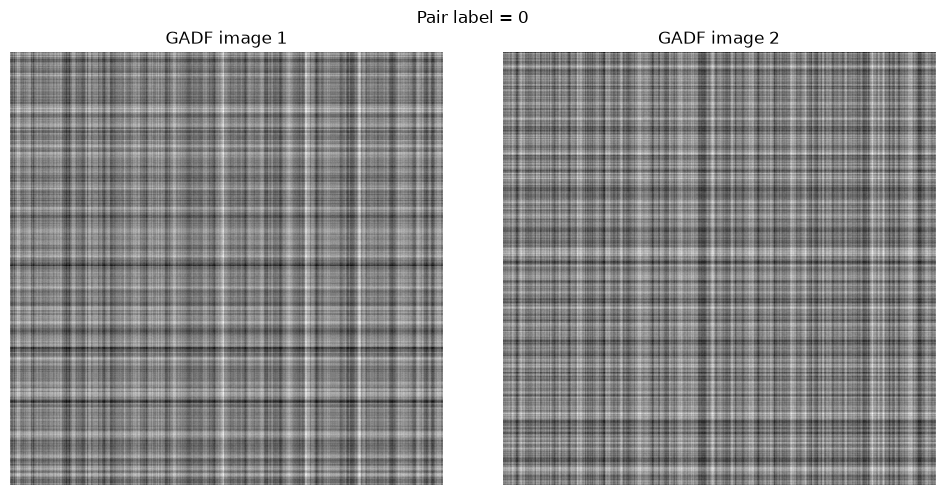

In [7]:
# ============================================================
# CELL 6 — Visualize one GADF pair
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5)
)

axes[0].imshow(
    image1[0, 0].numpy(),
    cmap="gray"
)

axes[0].set_title("GADF image 1")
axes[0].axis("off")

axes[1].imshow(
    image2[0, 0].numpy(),
    cmap="gray"
)

axes[1].set_title("GADF image 2")
axes[1].axis("off")

fig.suptitle(
    f"Pair label = {pair_label[0].item():.0f}"
)

plt.tight_layout()
plt.show()

In [8]:
# ============================================================
# CELL 7 — Create GADF Siamese Conv2D model
# ============================================================

model = Siamese2D(
    embedding_dim=128
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

print(model)

Siamese2D(
  (encoder): Conv2DEncoder(
    (features): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (7): ReLU()
      (8): AdaptiveAvgPool2d(output_size=(1, 1))
    )
    (embedding): Linear(in_features=128, out_features=128, bias=True)
  )
)


In [9]:
# ============================================================
# CELL 8 — Training functions
# ============================================================

MARGIN = 1.0


def run_epoch(
    model,
    loader,
    optimizer=None
):

    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    losses = []

    for image1, image2, labels in loader:

        image1 = image1.to(DEVICE)
        image2 = image2.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):

            z1, z2 = model(
                image1,
                image2
            )

            loss = contrastive_loss(
                z1,
                z2,
                labels,
                margin=MARGIN
            )

            if training:
                loss.backward()
                optimizer.step()

        losses.append(
            loss.item()
        )

    return float(
        np.mean(losses)
    )

In [10]:
# ============================================================
# CELL 9 — Train GADF 512x512
# ============================================================

NUM_EPOCHS = 20

best_val_loss = float("inf")

checkpoint_path = (
    MODEL_DIR
    / "fsl_gadf_512_best.pt"
)


for epoch in range(
    1,
    NUM_EPOCHS + 1
):

    train_loss = run_epoch(
        model,
        train_loader,
        optimizer
    )

    val_loss = run_epoch(
        model,
        val_loader,
        optimizer=None
    )

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train loss: {train_loss:.5f} | "
        f"Val loss: {val_loss:.5f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "val_loss": val_loss,
                "representation": "GADF",
                "image_size": 512,
                "embedding_dim": 128
            },
            checkpoint_path
        )

        print(
            "  ✓ Best checkpoint saved"
        )


print("\nTraining complete.")

print(
    "Best validation loss:",
    best_val_loss
)

print(
    "Checkpoint:",
    checkpoint_path
)

Epoch 01/20 | Train loss: 0.23411 | Val loss: 0.25782
  ✓ Best checkpoint saved
Epoch 02/20 | Train loss: 0.21661 | Val loss: 0.26920
Epoch 03/20 | Train loss: 0.20557 | Val loss: 0.28347
Epoch 04/20 | Train loss: 0.18880 | Val loss: 0.31448
Epoch 05/20 | Train loss: 0.16383 | Val loss: 0.31013
Epoch 06/20 | Train loss: 0.13521 | Val loss: 0.36354
Epoch 07/20 | Train loss: 0.10507 | Val loss: 0.35176
Epoch 08/20 | Train loss: 0.06676 | Val loss: 0.41814
Epoch 09/20 | Train loss: 0.05109 | Val loss: 0.38449
Epoch 10/20 | Train loss: 0.03664 | Val loss: 0.44812
Epoch 11/20 | Train loss: 0.02816 | Val loss: 0.44288
Epoch 12/20 | Train loss: 0.01953 | Val loss: 0.44658
Epoch 13/20 | Train loss: 0.01834 | Val loss: 0.51958
Epoch 14/20 | Train loss: 0.01936 | Val loss: 0.48729
Epoch 15/20 | Train loss: 0.01685 | Val loss: 0.42935
Epoch 16/20 | Train loss: 0.01499 | Val loss: 0.61245
Epoch 17/20 | Train loss: 0.01448 | Val loss: 0.45039
Epoch 18/20 | Train loss: 0.00929 | Val loss: 0.44755
Ep